In [188]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, optimize
from scipy import stats

In [189]:
# Identificación del grupo
C1 = 2028596201
C2 = 2035384971
S = C1 + C2                      # 4063981172

#Parámetros derivados de S
SEMILLA = S
TAU     = 180 + 10 * (S % 9)                         # 230 ms
EPS     = 0.01 * (1 + S % 3)                         # 0.03
CONF    = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]         # 0.99
ALPHA   = 1 - CONF
G_CREC  = 1.4 + 0.1 * (S % 7)                        # 2.0
T1      = 80 + 10 * (S % 5)                          # 100 KB
T2      = 400 + 25 * (S % 5)                         # 450 KB
PI      = (4 + S % 6) / 1000                         # 0.006
K_MAX   = 4 + (S % 5)                                # 6
R_DESP  = S % 6                                      # 2
N_CONS  = 10 + (S % 11)                              # 19
C0      = 2                                          # GPUs del pool real (enunciado)

#Única fuente de aleatoriedad del notebook
rng = np.random.default_rng(SEMILLA)

#Estilo de figuras
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

print(f"C1={C1}  C2={C2}  S={S}")
print(f"tau={TAU} ms | eps={EPS} | 1-alpha={CONF} | g={G_CREC:.1f}")
print(f"t1={T1} KB | t2={T2} KB | pi={PI} | k_max={K_MAX} | r={R_DESP} | N={N_CONS}")

C1=2028596201  C2=2035384971  S=4063981172
tau=230 ms | eps=0.03 | 1-alpha=0.99 | g=2.0
t1=100 KB | t2=450 KB | pi=0.006 | k_max=6 | r=2 | N=19


In [190]:
# Los archivos CSV están directamente en la carpeta actual.
RUTA = ""

sol_raw = pd.read_csv(RUTA + "solicitudes.csv")
mon_raw = pd.read_csv(RUTA + "monitoreo.csv")

# Copias de trabajo: los *_raw nunca se modifican
sol = sol_raw.copy()
mon = mon_raw.copy()

print("solicitudes:", sol_raw.shape)
print(sol_raw.dtypes, "\n")
print(sol_raw.head(), "\n")

print("monitoreo:", mon_raw.shape)
print(mon_raw.head())

solicitudes: (18518, 10)
id_solicitud      int64
t_llegada_s     float64
tam_kb          float64
cache_hit         int64
version          object
red_ms          float64
gpu_ms          float64
latencia_ms     float64
intentos          int64
exito             int64
dtype: object 

   id_solicitud  t_llegada_s  tam_kb  cache_hit version  red_ms  gpu_ms  \
0             1        0.027  114.37          0       B   42.64  -76.35   
1             2        0.130  140.45          0       B   57.96   53.52   
2             3        0.291   84.03          1       B   12.11    0.00   
3             4        0.436  162.24          0       B   28.69   61.08   
4             5        0.569  312.01          0       B   27.56   47.31   

   latencia_ms  intentos  exito  
0       118.99         1      1  
1       111.48         1      1  
2        12.11         1      1  
3        89.77         1      1  
4        74.87         1      1   

monitoreo: (6000, 4)
   minuto  D1  D2  incidente
0       1   

**C1.**

C1. Caracterización de la distribución completa de G

G = 0 si la solicitud utiliza caché.
G = X si la solicitud requiere procesamiento de GPU.


In [191]:

# 1. DATOS

cache_hit = rng.random(n) < p_true
g_cont = rng.lognormal(mu_true, sigma_true, n)

# Tiempo de GPU de todas las solicitudes
gpu_ms = np.where(cache_hit, 0.0, g_cont)

# Cuando tengan los datos reales, pueden reemplazar lo anterior por:
#
# import pandas as pd
# datos = pd.read_csv("solicitudes.csv")
# gpu_ms = datos["gpu_ms"].to_numpy(dtype=float)
# cache_hit = datos["cache_hit"].to_numpy() == 1          # <-- CAMBIO
# # Filas donde cache_hit y gpu_ms se contradicen (deben ir a la auditoría A1):
# print(((datos.cache_hit == 1) != (datos.gpu_ms == 0)).sum())   # <-- CAMBIO
# n = len(gpu_ms)

gpu_ms = np.asarray(gpu_ms, dtype=float)

if np.any(~np.isfinite(gpu_ms)) or np.any(gpu_ms < 0):
    raise ValueError("Los tiempos deben ser finitos y no negativos.")

n = len(gpu_ms)

if n == 0:
    raise ValueError("No hay observaciones.")


In [192]:
# 2. IDENTIFICACIÓN DE SOLICITUDES CACHEADAS Y NO CACHEADAS


# <-- CAMBIO: se eliminó "cache_hit = (gpu_ms == 0)"; se usa el cache_hit
#     definido en la sección 1 (en datos reales, la columna del CSV).

p_hat = cache_hit.mean()

# Parte continua: solicitudes que no utilizaron caché
x = gpu_ms[~cache_hit]

if len(x) < 2:
    raise ValueError("Se necesitan al menos dos solicitudes no cacheadas.")

print("C1. DISTRIBUCIÓN COMPLETA DE G")

print(f"Número total de solicitudes: {n}")
print(f"Solicitudes cacheadas: {cache_hit.sum()}")
print(f"Solicitudes no cacheadas: {len(x)}")
print(f"Probabilidad estimada de caché: {p_hat:.4f}")


C1. DISTRIBUCIÓN COMPLETA DE G
Número total de solicitudes: 5000
Solicitudes cacheadas: 1492
Solicitudes no cacheadas: 3508
Probabilidad estimada de caché: 0.2984


In [193]:
# 3. ESTIMACIÓN DE LOS PARÁMETROS DE LA PARTE CONTINUA

# Estimación de los parámetros de la lognormal
# (forma cerrada del MLE; coincide con el optimizador numérico de C2)
log_x = np.log(x)

mu = log_x.mean()
sigma = log_x.std(ddof=0)

print("\n PARÁMETROS DE LA PARTE CONTINUA ")
print(f"Mu = {mu:.6f}")
print(f"Sigma = {sigma:.6f}")



--- PARÁMETROS DE LA PARTE CONTINUA ---
Mu = 4.089710
Sigma = 0.404637


In [194]:
# 4. ESPERANZA Y VARIANZA TEÓRICAS DE G

# Momentos de la distribución lognormal
m = np.exp(mu + sigma**2 / 2)

s2 = (
    (np.exp(sigma**2) - 1)
    * np.exp(2 * mu + sigma**2)
)

# Esperanza de la mezcla
EG = (1 - p_hat) * m

# Varianza de la mezcla
VarG = (1 - p_hat) * s2 + p_hat * (1 - p_hat) * m**2

In [195]:
# 5. COMPARACIÓN CON LOS VALORES MUESTRALES

media_muestral = np.mean(gpu_ms)
varianza_muestral = np.var(gpu_ms, ddof=1)

print("\n COMPARACIÓN DE MOMENTOS ")

print(f"E[G] teórica       = {EG:.6f}")
print(f"E[G] muestral      = {media_muestral:.6f}")

print(f"Var(G) teórica     = {VarG:.6f}")
print(f"Var(G) muestral    = {varianza_muestral:.6f}")


--- COMPARACIÓN DE MOMENTOS ---
E[G] teórica       = 45.475935
E[G] muestral      = 45.446185
Var(G) teórica     = 1403.950221
Var(G) muestral    = 1387.610051


In [196]:
# 6. FUNCIÓN DE DISTRIBUCIÓN ACUMULADA DE G


dist_X = stats.lognorm(
    s=sigma,
    scale=np.exp(mu)
)

# Valores para representar la CDF
grid_G = np.linspace(
    0,
    np.quantile(gpu_ms, 0.995),
    500
)

# CDF teórica de la mezcla:
# F_G(g) = 0                         si g < 0
# F_G(g) = p + (1-p)F_X(g)          si g >= 0

cdf_G = p_hat + (1 - p_hat) * dist_X.cdf(grid_G)

# CDF empírica
g_ordenado = np.sort(gpu_ms)
probs_G = np.arange(1, n + 1) / n


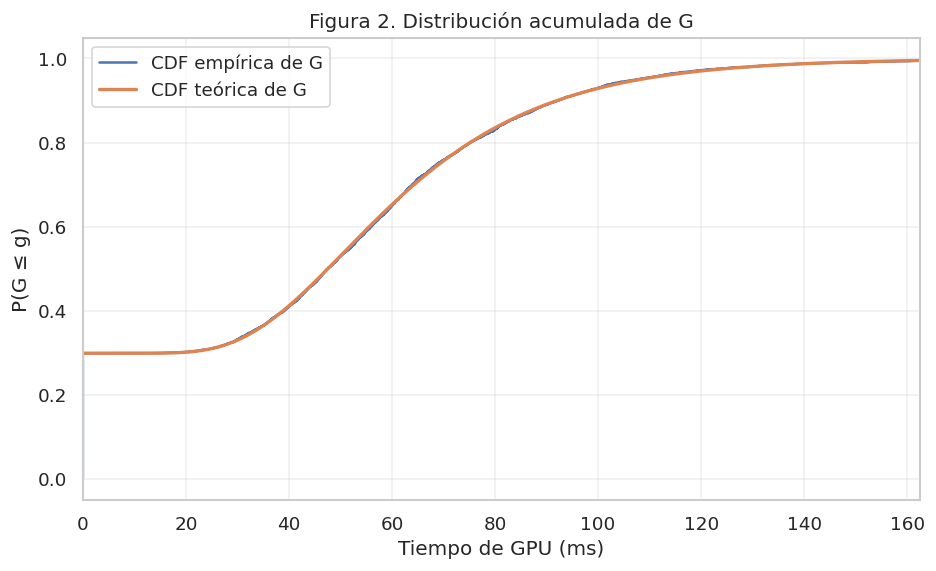

In [197]:

# 7. GRÁFICA DE LA DISTRIBUCIÓN COMPLETA

plt.figure(figsize=(9, 5))

plt.step(
    g_ordenado,
    probs_G,
    where="post",
    label="CDF empírica de G"
)

plt.plot(
    grid_G,
    cdf_G,
    label="CDF teórica de G",
    linewidth=2
)

plt.title("Figura 2. Distribución acumulada de G")   # <-- CAMBIO
plt.xlabel("Tiempo de GPU (ms)")
plt.ylabel("P(G ≤ g)")
plt.xlim(0, grid_G[-1])                              # <-- CAMBIO
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("figura_C1_CDF_G.png", dpi=200, bbox_inches="tight")
plt.show()

In [198]:
# 8. RESUMEN FINAL

print("RESUMEN FINAL C1")

print("Naturaleza de G: variable aleatoria mixta")
print(f"Masa de probabilidad en cero: {p_hat:.4f}")
print(f"Mu = {mu:.6f}")
print(f"Sigma = {sigma:.6f}")
print(f"Esperanza teórica = {EG:.6f}")
print(f"Esperanza muestral = {media_muestral:.6f}")
print(f"Varianza teórica = {VarG:.6f}")
print(f"Varianza muestral = {varianza_muestral:.6f}")

print("\nFigura guardada: figura_C1_CDF_G.png")

RESUMEN FINAL C1
Naturaleza de G: variable aleatoria mixta
Masa de probabilidad en cero: 0.2984
Mu = 4.089710
Sigma = 0.404637
Esperanza teórica = 45.475935
Esperanza muestral = 45.446185
Varianza teórica = 1403.950221
Varianza muestral = 1387.610051

Figura guardada: figura_C1_CDF_G.png


**C2.**

In [199]:
# PREPARACIÓN DE LOS DATOS

# Utilizar los datos que ya están cargados en el notebook.
# Si gpu_ms es el nombre de la columna/vector de tiempos:

gpu_ms = np.asarray(gpu_ms, dtype=float)

# Identificar solicitudes no cacheadas
x = gpu_ms[gpu_ms > 0]

# Cantidad de observaciones continuas
n_x = len(x)

if n_x < 2:
    raise ValueError("Se necesitan al menos dos observaciones positivas.")

if np.any(~np.isfinite(x)):
    raise ValueError("Hay datos no finitos en la muestra.")

print("C2: AJUSTE DE LA PARTE CONTINUA")
print("Total de observaciones continuas:", n_x)
print("Tiempo mínimo:", x.min())
print("Tiempo máximo:", x.max())
print("Media muestral:", x.mean())
print("Varianza muestral:", x.var(ddof=1))

C2: AJUSTE DE LA PARTE CONTINUA
Total de observaciones continuas: 3508
Tiempo mínimo: 13.489977302676676
Tiempo máximo: 212.23813895331332
Media muestral: 64.77506469083616
Varianza muestral: 725.5613012475281


In [200]:
# LOG-VEROSIMILITUD

def neg_loglik(theta, datos):

    mu, log_sigma = theta

    # Garantizar que sigma sea positivo
    sigma = np.exp(log_sigma)

    if not np.isfinite(sigma) or sigma <= 0:
        return np.inf

    log_datos = np.log(datos)

    log_verosimilitud = (
        -np.sum(log_datos)
        -len(datos) * np.log(sigma)
        -0.5 * len(datos) * np.log(2 * np.pi)
        -np.sum((log_datos - mu)**2) / (2 * sigma**2)
    )

    return -log_verosimilitud

In [201]:
# MÁXIMA VEROSIMILITUD

# Valores iniciales
x0 = np.array([
    np.log(x).mean(),
    np.log(np.log(x).std(ddof=0))
])

# Optimización numérica
res = optimize.minimize(
    neg_loglik,
    x0,
    args=(x,),
    method="Nelder-Mead"
)

if not res.success:
    raise RuntimeError("La optimización MLE no convergió.")

mu_mle = res.x[0]
sigma_mle = np.exp(res.x[1])

loglik_mle = -res.fun

print("RESULTADOS MLE")
print("Mu:", mu_mle)
print("Sigma:", sigma_mle)
print("Log-verosimilitud:", loglik_mle)


RESULTADOS MLE
Mu: 4.0897097116852414
Sigma: 0.4046366377246362
Log-verosimilitud: -16150.419597746306


In [202]:
# COMPARACIÓN DE ESTIMACIONES
# Calcular estimadores por el Método de los Momentos (MOM)
m1 = x.mean()
m2 = x.var(ddof=0) # Varianza muestral sesgada (momento de la muestra)

mu_mom = np.log(m1**2 / np.sqrt(m2 + m1**2))
sigma_mom = np.sqrt(np.log(1 + m2 / m1**2))

dist_mle = stats.lognorm(
    s=sigma_mle,
    scale=np.exp(mu_mle)
)

dist_mom = stats.lognorm(
    s=sigma_mom,
    scale=np.exp(mu_mom)
)

loglik_mom = -neg_loglik(
    [mu_mom, np.log(sigma_mom)],
    x
)

print("COMPARACIÓN DE MÉTODOS")
print(f"Mu MLE: {mu_mle:.6f}")
print(f"Mu momentos: {mu_mom:.6f}")

print(f"Sigma MLE: {sigma_mle:.6f}")
print(f"Sigma momentos: {sigma_mom:.6f}")

print(f"Log-verosimilitud MLE: {loglik_mle:.6f}")
print(f"Log-verosimilitud momentos: {loglik_mom:.6f}")

COMPARACIÓN DE MÉTODOS
--------------------------------
Mu MLE: 4.089710
Mu momentos: 4.091191
Sigma MLE: 0.404637
Sigma momentos: 0.399323
Log-verosimilitud MLE: -16150.419598
Log-verosimilitud momentos: -16151.062178


In [203]:
#PRUEBA KOLMOGOROV-SMIRNOV

ks = stats.kstest(x, dist_mle.cdf)

print("BONDAD DE AJUSTE")
print(f"Estadístico KS: {ks.statistic:.6f}")
print(f"Valor p convencional: {ks.pvalue:.6f}")

print(
    "Nota: el valor p convencional no está calibrado "
    "porque los parámetros se estimaron con estos mismos datos."
)


BONDAD DE AJUSTE
--------------------------------
Estadístico KS: 0.009933
Valor p convencional: 0.875871
Nota: el valor p convencional no está calibrado porque los parámetros se estimaron con estos mismos datos.


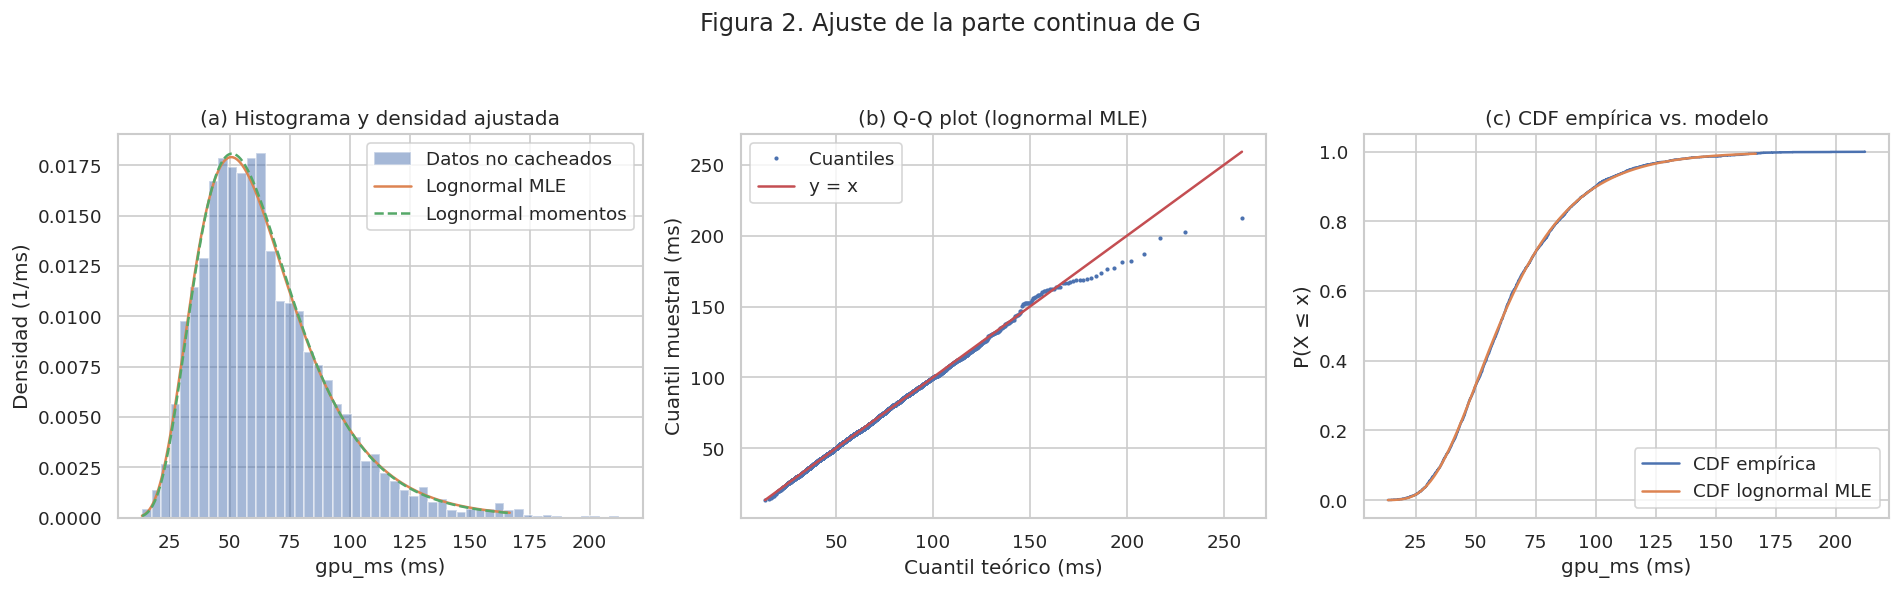

In [204]:
#HISTOGRAMA Y DENSIDADES

grid = np.linspace(
    x.min(),
    np.quantile(x, 0.995),
    400
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].hist(
    x,
    bins=50,
    density=True,
    alpha=0.5,
    label="Datos no cacheados"
)

ax[0].plot(
    grid,
    dist_mle.pdf(grid),
    label="Lognormal MLE"
)

ax[0].plot(
    grid,
    dist_mom.pdf(grid),
    "--",
    label="Lognormal momentos"
)

ax[0].set(
    title="(a) Histograma y densidad ajustada",
    xlabel="gpu_ms (ms)",
    ylabel="Densidad (1/ms)"
)

ax[0].legend()

# GRÁFICO Q-Q
probs = (np.arange(1, n_x + 1) - 0.5) / n_x

q_teo = dist_mle.ppf(probs)
q_mue = np.sort(x)

ax[1].plot(
    q_teo,
    q_mue,
    ".",
    markersize=3,
    label="Cuantiles"
)

lim = [
    min(q_teo.min(), q_mue.min()),
    max(q_teo.max(), q_mue.max())
]

ax[1].plot(
    lim,
    lim,
    "r-",
    label="y = x"
)

ax[1].set(
    title="(b) Q-Q plot (lognormal MLE)",
    xlabel="Cuantil teórico (ms)",
    ylabel="Cuantil muestral (ms)"
)

ax[1].legend()

#CDF EMPÍRICA Y TEÓRICA

ax[2].step(
    q_mue,
    np.arange(1, n_x + 1) / n_x,
    where="post",
    label="CDF empírica"
)

ax[2].plot(
    grid,
    dist_mle.cdf(grid),
    label="CDF lognormal MLE"
)

ax[2].set(
    title="(c) CDF empírica vs. modelo",
    xlabel="gpu_ms (ms)",
    ylabel="P(X ≤ x)"
)

ax[2].legend()

fig.suptitle("Figura 2. Ajuste de la parte continua de G")
fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    "figura2_ajuste_G.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [205]:
#INTERVALOS DE CONFIANZA DE WALD

z = stats.norm.ppf(1 - ALPHA / 2)

# Intervalo para mu
ic_mu = (
    mu_mle - z * sigma_mle / np.sqrt(n_x),
    mu_mle + z * sigma_mle / np.sqrt(n_x)
)

# Intervalo para sigma
ic_sigma = (
    sigma_mle - z * sigma_mle / np.sqrt(2 * n_x),
    sigma_mle + z * sigma_mle / np.sqrt(2 * n_x)
)

print(f"INTERVALOS DE CONFIANZA AL {CONF:.0%}")

print(
    f"Mu: [{ic_mu[0]:.6f}, {ic_mu[1]:.6f}]"
)

print(
    f"Sigma: [{ic_sigma[0]:.6f}, {ic_sigma[1]:.6f}]"
)


INTERVALOS DE CONFIANZA AL 99%
Mu: [4.072112, 4.107307]
Sigma: [0.392193, 0.417080]


In [206]:
# BOOTSTRAP

B = 2000

boot_mu = np.empty(B)
boot_sigma = np.empty(B)

for b in range(B):

    xb = rng.choice(
        x,
        size=n_x,
        replace=True
    )

    log_xb = np.log(xb)

    boot_mu[b] = log_xb.mean()

    boot_sigma[b] = np.sqrt(
        np.mean((log_xb - boot_mu[b])**2)
    )

lo = 100 * ALPHA / 2
hi = 100 * (1 - ALPHA / 2)

ic_mu_boot = np.percentile(
    boot_mu,
    [lo, hi]
)

ic_sigma_boot = np.percentile(
    boot_sigma,
    [lo, hi]
)

print("INTERVALOS BOOTSTRAP")

print(
    f"Mu: [{ic_mu_boot[0]:.6f}, {ic_mu_boot[1]:.6f}]"
)

print(
    f"Sigma: [{ic_sigma_boot[0]:.6f}, {ic_sigma_boot[1]:.6f}]"
)


INTERVALOS BOOTSTRAP
Mu: [4.071449, 4.107229]
Sigma: [0.393122, 0.417521]


In [207]:
#KS CON BOOTSTRAP PARAMÉTRICO

B_KS = 2000

D_observado = ks.statistic
D_simulados = np.empty(B_KS)

for b in range(B_KS):

    # Simular datos bajo el modelo ajustado
    xb = rng.lognormal(
        mean=mu_mle,
        sigma=sigma_mle,
        size=n_x
    )

    # Reestimar los parámetros
    log_xb = np.log(xb)

    mu_b = log_xb.mean()
    sigma_b = log_xb.std(ddof=0)

    dist_b = stats.lognorm(
        s=sigma_b,
        scale=np.exp(mu_b)
    )

    # Calcular estadístico KS
    D_simulados[b] = stats.kstest(
        xb,
        dist_b.cdf
    ).statistic

# Valor p bootstrap
p_boot_KS = (
    1 + np.sum(D_simulados >= D_observado)
) / (B_KS + 1)

print("KS CON BOOTSTRAP PARAMÉTRICO")
print(f"KS observado: {D_observado:.6f}")
print(f"Valor p bootstrap: {p_boot_KS:.6f}")


KS CON BOOTSTRAP PARAMÉTRICO
KS observado: 0.009933
Valor p bootstrap: 0.567716


In [208]:
#RESUMEN FINAL

print("RESUMEN FINAL C2")

print(f"Observaciones: {n_x}")

print(f"Mu MLE: {mu_mle:.6f}")

print(f"Sigma MLE: {sigma_mle:.6f}")

print(f"Mu momentos: {mu_mom:.6f}")

print(f"Sigma momentos: {sigma_mom:.6f}")

print(f"Log-verosimilitud MLE: {loglik_mle:.6f}")

print(f"Log-verosimilitud momentos: {loglik_mom:.6f}")

print(f"KS: {ks.statistic:.6f}")

print(f"p convencional: {ks.pvalue:.6f}")

print(f"p bootstrap: {p_boot_KS:.6f}")

print(f"Confianza: {CONF:.0%}")

print("\nFigura guardada: figura2_ajuste_G.png")


RESUMEN FINAL C2
Observaciones: 3508
Mu MLE: 4.089710
Sigma MLE: 0.404637
Mu momentos: 4.091191
Sigma momentos: 0.399323
Log-verosimilitud MLE: -16150.419598
Log-verosimilitud momentos: -16151.062178
KS: 0.009933
p convencional: 0.875871
p bootstrap: 0.567716
Confianza: 99%

Figura guardada: figura2_ajuste_G.png


In [209]:

df_nc = sol[sol.cache_hit == 0]
clase = pd.cut(df_nc.tam_kb, [0, 100, 450, np.inf], right=False)
print(df_nc.groupby(clase)["gpu_ms"].agg(["count", "mean", "std"]))
print(df_nc.groupby("version")["gpu_ms"].agg(["count", "mean", "std"]))
print("Kruskal-Wallis por clase:", stats.kruskal(*[g.gpu_ms for _, g in df_nc.groupby(clase)]))

                count        mean        std
tam_kb                                      
[0.0, 100.0)     2386   37.430096  17.034046
[100.0, 450.0)   8511   71.192886  38.237513
[450.0, inf)     1219  174.276489  97.317638
         count       mean        std
version                             
A         5998  78.545097  61.034325
B         6113  71.354345  53.776385
a            3  53.326667  17.021458
b            4  76.090000  33.610148
Kruskal-Wallis por clase: KruskalResult(statistic=np.float64(4189.1600461942035), pvalue=np.float64(0.0))


/tmp/ipykernel_4256/3018387096.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df_nc.groupby(clase)["gpu_ms"].agg(["count", "mean", "std"]))
/tmp/ipykernel_4256/3018387096.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("Kruskal-Wallis por clase:", stats.kruskal(*[g.gpu_ms for _, g in df_nc.groupby(clase)]))


**C3.**

In [210]:
# C3. ¿red_ms admite un modelo normal?
# Extraer los datos reales del DataFrame cargado
red_ms = sol["red_ms"].to_numpy(dtype=float)

n_r = len(red_ms)
mu_r, sd_r = red_ms.mean(), red_ms.std(ddof=1)
print("\n C3")
print(f"media = {mu_r:.3f} ms, desv. est. = {sd_r:.3f} ms")

# Criterio 1: asimetría y curtosis (normal: 0 y 0)
asim, curt = stats.skew(red_ms), stats.kurtosis(red_ms)   # curtosis en exceso
print(f"asimetría = {asim:.3f}, curtosis en exceso = {curt:.3f}")
# Criterio 2: Shapiro-Wilk (H0: normal)
sw = stats.shapiro(red_ms)
print(f"Shapiro-Wilk: W = {sw.statistic:.4f}, p = {sw.pvalue:.3g}")
# Criterio 3: D'Agostino-Pearson (basado en asimetría y curtosis)
dp = stats.normaltest(red_ms)
print(f"D'Agostino-Pearson: K2 = {dp.statistic:.2f}, p = {dp.pvalue:.3g}")
# Criterio 4 (gráfico): Q-Q plot, en la Figura 3

# P(red > x) para tres valores de x: empírica (con IC Wilson) vs. modelo normal
print(f"\nP(red > x), IC Wilson al {CONF:.0%}:")
for x_val in [50.0, 60.0, 80.0]:                          # <-- ajustar a sus datos
    k = int((red_ms > x_val).sum())
    p_emp = k / n_r
    ci = stats.binomtest(k, n_r).proportion_ci(confidence_level=CONF, method="wilson")
    p_norm = 1 - stats.norm.cdf(x_val, mu_r, sd_r)
    print(f"x = {x_val:5.1f} | empírica = {p_emp:.4f} [{ci.low:.4f}, {ci.high:.4f}]"
          f" | modelo normal = {p_norm:.4f}")

# Percentil 99,9 %: puntual, IC bootstrap percentil, y percentil del modelo normal
q_emp = np.quantile(red_ms, 0.999)
B = 2000
boot_q = np.quantile(rng.choice(red_ms, size=(B, n_r), replace=True), 0.999, axis=1)
q_lo, q_hi = np.percentile(boot_q, [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])
q_norm = stats.norm.ppf(0.999, mu_r, sd_r)
print(f"\nPercentil 99,9 %: empírico = {q_emp:.2f} ms, "
      f"IC bootstrap {CONF:.0%} = [{q_lo:.2f}, {q_hi:.2f}] | normal = {q_norm:.2f} ms")


 C3
media = nan ms, desv. est. = nan ms
asimetría = nan, curtosis en exceso = nan
Shapiro-Wilk: W = nan, p = nan
D'Agostino-Pearson: K2 = nan, p = nan

P(red > x), IC Wilson al 99%:
x =  50.0 | empírica = 0.1377 [0.1313, 0.1444] | modelo normal = nan
x =  60.0 | empírica = 0.0697 [0.0650, 0.0746] | modelo normal = nan
x =  80.0 | empírica = 0.0187 [0.0163, 0.0214] | modelo normal = nan

Percentil 99,9 %: empírico = nan ms, IC bootstrap 99% = [nan, nan] | normal = nan ms


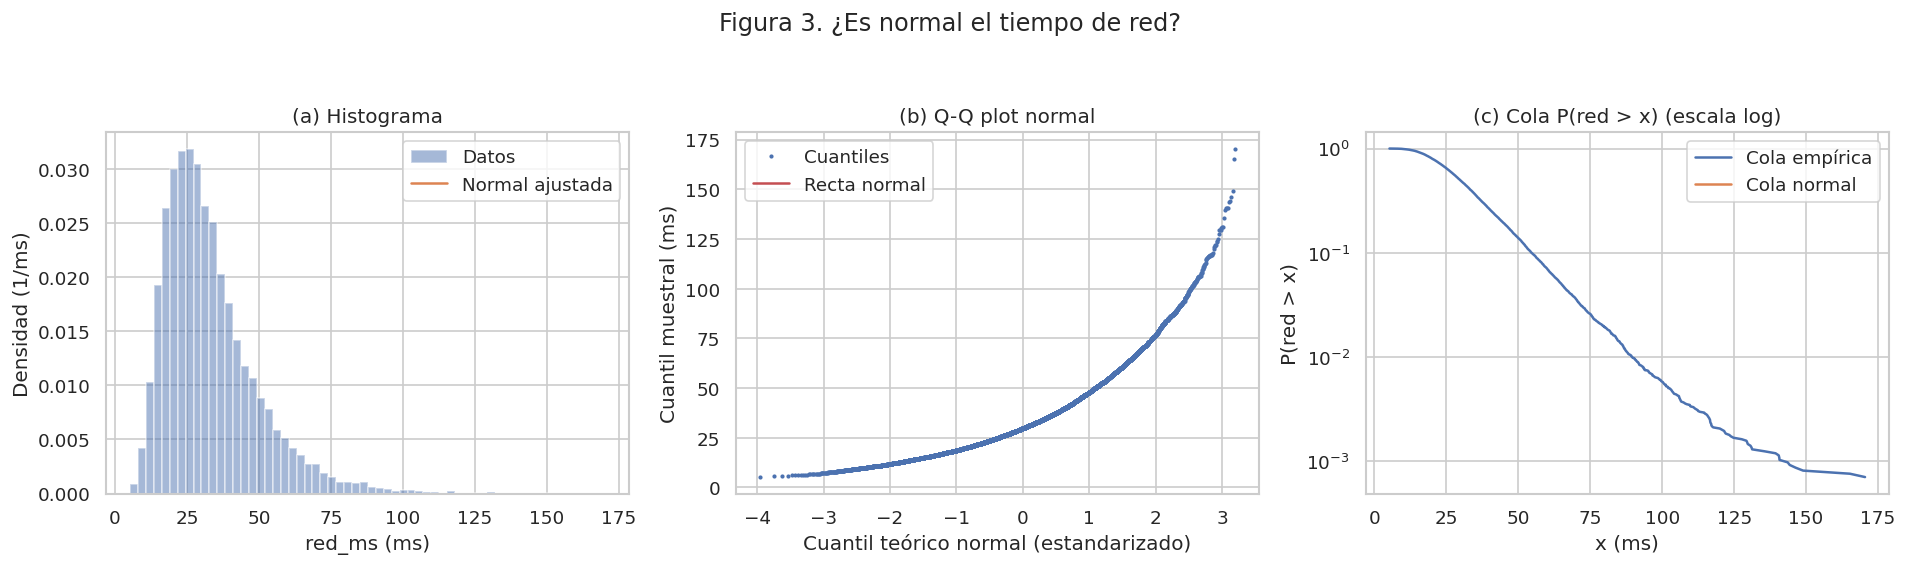

In [211]:
# Figura 3
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
grid = np.linspace(red_ms.min(), np.quantile(red_ms, 0.999), 400)
ax[0].hist(red_ms, bins=60, density=True, alpha=0.5, label="Datos")
ax[0].plot(grid, stats.norm.pdf(grid, mu_r, sd_r), label="Normal ajustada")
ax[0].set(title="(a) Histograma", xlabel="red_ms (ms)", ylabel="Densidad (1/ms)")
ax[0].legend()
(osm, osr), (sl, ic_, r) = stats.probplot(red_ms, dist="norm")
ax[1].plot(osm, osr, ".", markersize=3, label="Cuantiles")
ax[1].plot(osm, sl * np.asarray(osm) + ic_, "r-", label="Recta normal")
ax[1].set(title="(b) Q-Q plot normal", xlabel="Cuantil teórico normal (estandarizado)",
          ylabel="Cuantil muestral (ms)")
ax[1].legend()
xs = np.sort(red_ms)
ax[2].semilogy(xs, 1 - np.arange(1, n_r + 1) / n_r + 1 / n_r, label="Cola empírica")
ax[2].semilogy(xs, 1 - stats.norm.cdf(xs, mu_r, sd_r), label="Cola normal")
ax[2].set(title="(c) Cola P(red > x) (escala log)", xlabel="x (ms)", ylabel="P(red > x)")
ax[2].legend()
fig.suptitle("Figura 3. ¿Es normal el tiempo de red?")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("figura3_red.png", dpi=200, bbox_inches="tight")
plt.show()



**C4.**


C4. Suma de N tiempos de GPU. Datos SINTÉTICOS solo para probar el código.
Con los datos reales, reemplazar la sección 1 por la lectura de solicitudes.csv.
Todos los parámetros del grupo se derivan de S (ver tabla del enunciado).

In [212]:
# C4. P(T_N > N (m_hat + 15)), T_N = suma de N tiempos de GPU no cacheados
N = N_CONS                                   # Definir N usando el valor derivado N_CONS
x_nc = gpu_ms[~cache_hit]
m_hat = x_nc.mean()                          # media muestral (la pide el enunciado)
s_hat = x_nc.std(ddof=1)
umbral = N * (m_hat + 15)
log_x = np.log(x_nc)
mu_ln, sig_ln = log_x.mean(), log_x.std(ddof=0)       # lognormal de la parte continua
m_ln = np.exp(mu_ln + sig_ln**2 / 2)
print(f"\n C4  N = {N}, m_hat = {m_hat:.3f}, s_hat = {s_hat:.3f}, "
      f"umbral = {umbral:.2f} ms")


 C4  N = 19, m_hat = 64.775, s_hat = 26.936, umbral = 1515.73 ms


In [213]:
# Aproximación 1: Teorema Central del Límite, T_N ~ Normal(N m, N s^2)
z = (umbral - N * m_hat) / (np.sqrt(N) * s_hat)
p_tcl = 1 - stats.norm.cdf(z)


In [214]:
# Aproximación 2: Fenton-Wilkinson, la suma de lognormales ~ lognormal con
# los mismos dos primeros momentos que T_N
sig_s2 = np.log(1 + (np.exp(sig_ln**2) - 1) / N)
mu_s = np.log(N * m_ln) - sig_s2 / 2
p_fw = 1 - stats.lognorm.cdf(umbral, s=np.sqrt(sig_s2), scale=np.exp(mu_s))


In [215]:
# Simulación de Montecarlo (referencia): sumas de N lognormales ajustadas
M = 1_000_000
T = rng.lognormal(mu_ln, sig_ln, size=(M, N)).sum(axis=1)
k_sim = int((T > umbral).sum())
p_sim = k_sim / M
ci_sim = stats.binomtest(k_sim, M).proportion_ci(confidence_level=CONF, method="wilson")

print(f"TCL (normal)            : {p_tcl:.5f}")
print(f"Fenton-Wilkinson (logn.): {p_fw:.5f}")
print(f"Simulación (M={M:,})  : {p_sim:.5f}  IC {CONF:.0%} [{ci_sim.low:.5f}, {ci_sim.high:.5f}]")
print(f"Error relativo TCL = {100*(p_tcl-p_sim)/p_sim:+.1f} %, "
      f"FW = {100*(p_fw-p_sim)/p_sim:+.1f} %")


TCL (normal)            : 0.00760
Fenton-Wilkinson (logn.): 0.01394
Simulación (M=1,000,000)  : 0.01415  IC 99% [0.01385, 0.01446]
Error relativo TCL = -46.3 %, FW = -1.6 %


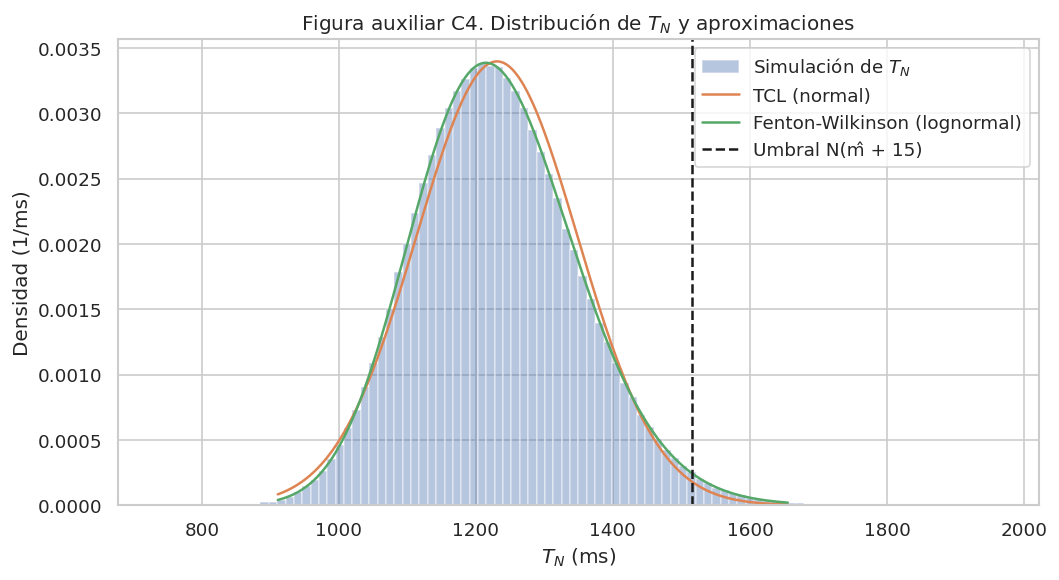

In [216]:
# Figura de apoyo C4: distribución de T_N y las dos aproximaciones
fig2, ax2 = plt.subplots(figsize=(9, 5))
g2 = np.linspace(np.quantile(T, 0.001), np.quantile(T, 0.999), 400)
ax2.hist(T, bins=100, density=True, alpha=0.4, label="Simulación de $T_N$")
ax2.plot(g2, stats.norm.pdf(g2, N * m_hat, np.sqrt(N) * s_hat), label="TCL (normal)")
ax2.plot(g2, stats.lognorm.pdf(g2, s=np.sqrt(sig_s2), scale=np.exp(mu_s)),
         label="Fenton-Wilkinson (lognormal)")
ax2.axvline(umbral, color="k", linestyle="--", label="Umbral N(m̂ + 15)")
ax2.set(title="Figura auxiliar C4. Distribución de $T_N$ y aproximaciones",
        xlabel="$T_N$ (ms)", ylabel="Densidad (1/ms)")
ax2.legend()
fig2.tight_layout()
fig2.savefig("figura_aux_C4.png", dpi=200, bbox_inches="tight")
plt.show()